# Fourier analysis of a vibration signal

An accelerometer on a gearbox records a noisy vibration. This notebook finds what it is made of and turns each
step into a scene of a SciView film:

1. **The signal**: 2 s sampled at 1 kHz, three tones buried in noise.
2. **The spectrum**: the discrete Fourier transform, and why a window matters.
3. **The peaks**: three frequencies found automatically, refined between the bins.
4. **The fit**: amplitude, frequency and phase of each tone, with uncertainties.
5. **The filter**: keep only the peaks, transform back, and measure how much cleaner the signal is.
6. **The film**: five scenes made from these results, rendered to MP4.

The recording is simulated, so every number can be checked against the truth. To use your own data, replace
`signal` and `FS` in step 1 and keep the rest.

Install: `pip install "sciview[math,science]"` (SciPy does the analysis).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares
from scipy.signal import find_peaks

import sciview as sv
from sciview.jupyter import still

FILM = Path("films/fourier")
ASSETS = FILM / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(3)
print("SciView", sv.__version__)

SciView 1.0.0


## 1. The signal

Three tones: the shaft turning (12.3 Hz), the gear teeth meshing (37.1 Hz) and a worn bearing (85.6 Hz), plus
white noise stronger than the two smaller tones. The frequencies fall between the frequency bins on purpose,
as real ones do.

2000 samples, SNR of the recording 1.8 dB


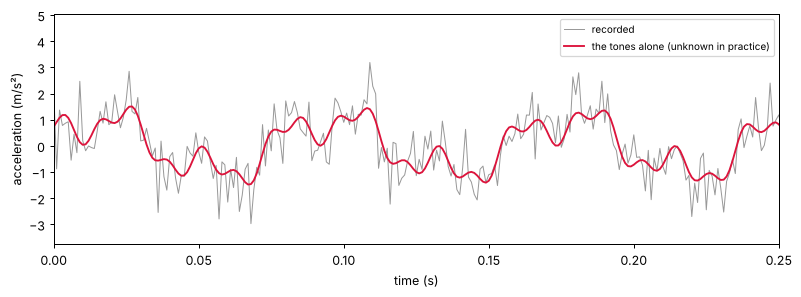

In [2]:
FS, T = 1000.0, 2.0                                   # sampling rate (Hz) and length (s)
t = np.arange(int(FS * T)) / FS
TRUE = [(12.3, 1.00, 0.4), (37.1, 0.60, 1.9), (85.6, 0.35, -0.7)]     # frequency (Hz), amplitude (m/s²), phase
NAMES = ["shaft", "gear mesh", "bearing"]
NOISE = 0.7

clean = sum(a * np.sin(2 * np.pi * f * t + p) for f, a, p in TRUE)
signal = clean + rng.normal(0, NOISE, t.size)


def snr_db(x, reference):
    """Signal-to-noise ratio of x against the noiseless reference, in dB."""
    return 10 * np.log10(np.mean(reference ** 2) / np.mean((x - reference) ** 2))


snr_raw = snr_db(signal, clean)
print(f"{t.size} samples, SNR of the recording {snr_raw:.1f} dB")

fig, ax = plt.subplots()
ax.plot(t, signal, color="0.6", lw=0.8, label="recorded")
ax.plot(t, clean, color="crimson", lw=1.5, label="the tones alone (unknown in practice)")
ax.set_xlim(0, 0.25)
ax.set_xlabel("time (s)")
ax.set_ylabel("acceleration (m/s²)")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()

## 2. The spectrum

The discrete Fourier transform writes the $N$ samples as a sum of $N/2+1$ sinusoids at the frequencies
$f_k = k\,f_s/N$, here every 0.5 Hz:

$$X_k = \sum_{n=0}^{N-1} w_n\, x_n\, e^{-2\pi i\, k n / N}$$

With $w_n = 1$ (no window) a tone between two bins leaks into all the others and hides the small peaks. A Hann
window tapers the ends of the record and keeps each peak narrow. The amplitude spectrum is $2|X_k| / \sum w_n$,
so a peak's height is the tone's amplitude.

1001 frequencies, resolution 0.5 Hz, up to 500 Hz


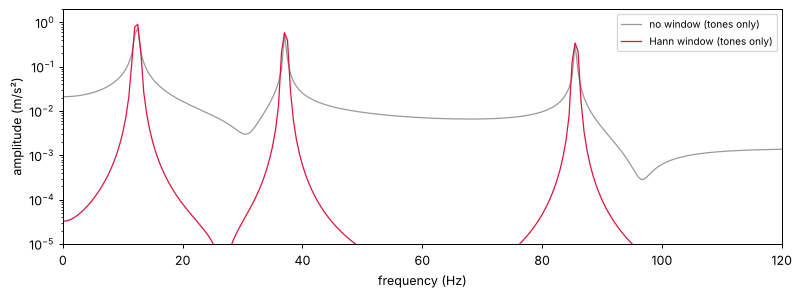

In [3]:
N = t.size
freqs = np.fft.rfftfreq(N, 1 / FS)
DF = freqs[1]


def amplitude_spectrum(x, window):
    return 2 * np.abs(np.fft.rfft(x * window)) / window.sum()


rect = amplitude_spectrum(signal, np.ones(N))
hann_window = np.hanning(N)
spec = amplitude_spectrum(signal, hann_window)
print(f"{freqs.size} frequencies, resolution {DF} Hz, up to {freqs[-1]:.0f} Hz")

fig, ax = plt.subplots()
ax.semilogy(freqs, amplitude_spectrum(clean, np.ones(N)), color="0.6", lw=1, label="no window (tones only)")
ax.semilogy(freqs, amplitude_spectrum(clean, hann_window), color="crimson", lw=1, label="Hann window (tones only)")
ax.set_xlim(0, 120)
ax.set_ylim(1e-5, 2)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("amplitude (m/s²)")
ax.legend(fontsize=8)
fig.tight_layout()

## 3. The peaks

The noise floor is estimated from the median of the spectrum; a peak counts if it stands well above it. Each
peak's true frequency lies between bins: a parabola through the logarithm of the three highest bins puts it
within a few hundredths of a hertz.

In [4]:
floor = np.median(spec)
threshold = 8 * floor
idx, _ = find_peaks(spec, height=threshold, distance=int(2 / DF))
idx = idx[np.argsort(freqs[idx])]


def refine(k):
    """Frequency of a peak from a parabola through the log amplitudes of bins k-1, k, k+1."""
    a, b, c = np.log(spec[k - 1:k + 2])
    return freqs[k] + 0.5 * (a - c) / (a - 2 * b + c) * DF


peak_f = np.array([refine(k) for k in idx])
print(f"noise floor {floor:.4f}, threshold {threshold:.3f}")
for k, f in zip(idx, peak_f):
    print(f"  peak at bin {k} ({freqs[k]:.1f} Hz) -> {f:.2f} Hz, height {spec[k]:.3f}")

noise floor 0.0318, threshold 0.254
  peak at bin 25 (12.5 Hz) -> 12.30 Hz, height 0.930
  peak at bin 74 (37.0 Hz) -> 37.12 Hz, height 0.545
  peak at bin 171 (85.5 Hz) -> 85.58 Hz, height 0.345


## 4. The fit

The spectrum's peak heights are biased by where the tone falls between bins. A least-squares fit of three
sines to the samples, started from the peaks, gives amplitude, frequency and phase, and the covariance of the
fit gives their uncertainties.

In [5]:
def model(params, t):
    f, a, p = params.reshape(-1, 3).T
    return (a[:, None] * np.sin(2 * np.pi * f[:, None] * t + p[:, None])).sum(0)


start = []
for f in peak_f:                               # amplitude and phase at a fixed frequency: a linear fit
    basis = np.c_[np.sin(2 * np.pi * f * t), np.cos(2 * np.pi * f * t)]
    s, c = np.linalg.lstsq(basis, signal, rcond=None)[0]
    start += [f, np.hypot(s, c), np.arctan2(c, s)]

fit = least_squares(lambda q: model(q, t) - signal, np.array(start))
residual = fit.fun
sigma = residual.std(ddof=len(fit.x))
cov = np.linalg.inv(fit.jac.T @ fit.jac) * sigma ** 2
err = np.sqrt(np.diag(cov))
est = fit.x.reshape(-1, 3)
est_err = err.reshape(-1, 3)
est[:, 2] = (est[:, 2] + np.pi) % (2 * np.pi) - np.pi

print(f"noise estimated from the residual {sigma:.3f} (true {NOISE})")
print(f"{'':10s} {'frequency (Hz)':>20s} {'amplitude':>18s} {'phase (rad)':>18s}")
for name, (f, a, p), (df, da, dp), (tf, ta, tp) in zip(NAMES, est, est_err, TRUE):
    print(f"{name:10s} {f:9.3f} ± {df:.3f} ({tf}) {a:7.3f} ± {da:.3f} ({ta}) {p:7.2f} ± {dp:.2f} ({tp})")

noise estimated from the residual 0.695 (true 0.7)
                 frequency (Hz)          amplitude        phase (rad)
shaft         12.305 ± 0.006 (12.3)   1.049 ± 0.022 (1.0)    0.36 ± 0.04 (0.4)
gear mesh     37.094 ± 0.010 (37.1)   0.583 ± 0.022 (0.6)    1.92 ± 0.08 (1.9)
bearing       85.572 ± 0.018 (85.6)   0.343 ± 0.022 (0.35)   -0.55 ± 0.13 (-0.7)


## 5. The filter

Two ways to clean the signal. A **spectral mask** keeps the bins within 2 Hz of each peak (with soft edges) and
transforms back; it needs no model. The **fitted model** keeps only the three sines. Both are compared with the
noiseless tones.

SNR: recording 1.8 dB, spectral mask 13.5 dB, fitted model 25.0 dB


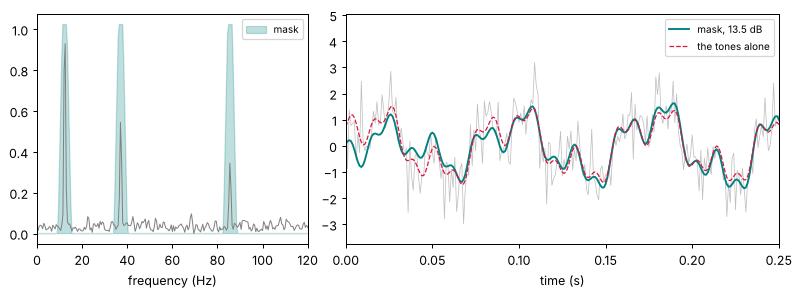

In [6]:
mask = np.zeros_like(freqs)
for f in peak_f:
    mask = np.maximum(mask, np.clip(1.5 - np.abs(freqs - f) / 2.0, 0, 1))   # flat ±1 Hz, zero beyond ±3 Hz
filtered = np.fft.irfft(np.fft.rfft(signal) * mask, n=N)
fitted = model(fit.x, t)

snr_filtered = snr_db(filtered, clean)
snr_model = snr_db(fitted, clean)
print(f"SNR: recording {snr_raw:.1f} dB, spectral mask {snr_filtered:.1f} dB, fitted model {snr_model:.1f} dB")

fig, ax = plt.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].plot(freqs, spec, color="0.5", lw=0.8)
ax[0].fill_between(freqs, 0, mask * spec.max() * 1.1, color="teal", alpha=0.25, label="mask")
ax[0].set_xlim(0, 120)
ax[0].set_xlabel("frequency (Hz)")
ax[0].legend(fontsize=8)
ax[1].plot(t, signal, color="0.75", lw=0.6)
ax[1].plot(t, filtered, color="teal", lw=1.5, label=f"mask, {snr_filtered:.1f} dB")
ax[1].plot(t, clean, color="crimson", lw=1, ls="--", label="the tones alone")
ax[1].set_xlim(0, 0.25)
ax[1].set_xlabel("time (s)")
ax[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()

## 6. The film

The film's data are a few CSV files in its `assets` folder: the first quarter second of the signals, the
spectrum and the mask, and the three tones laid out in 3D for the scene that explains what a spectrum is.

In [7]:
WINDOW = t < 0.25
np.savetxt(ASSETS / "signal.csv", np.c_[t, signal, clean, filtered, fitted][WINDOW], delimiter=",",
           header="t,recorded,clean,filtered,fitted", comments="", fmt="%.5f")
SHOW = freqs <= 120
np.savetxt(ASSETS / "spectrum.csv", np.c_[freqs, spec, mask * 1.15][SHOW], delimiter=",",
           header="f,amplitude,mask", comments="", fmt="%.5f")

# The 3D scene: time along x, frequency along y, acceleration up (z). One file per tone, plus their sum.
TX, FY, AZ = 80 / 0.25, 0.6, 11            # scene units per second, per hertz, per m/s²
t3 = np.linspace(0, 0.25, 3000)


def save_xyz(name, z, y=0.0):
    np.savetxt(ASSETS / name, np.c_[t3 * TX - 40, np.full_like(t3, y), z * AZ], delimiter=",",
               header="x,y,z", comments="", fmt="%.3f")


save_xyz("sum.csv", sum(a * np.sin(2 * np.pi * f * t3 + p) for f, a, p in est))
for i, (f, a, p) in enumerate(est):
    save_xyz(f"tone_{i}.csv", a * np.sin(2 * np.pi * f * t3 + p))

film = sv.Project(path=FILM / "fourier.sciview.json", title="What is a vibration made of?",
                  author="SciView example", duration=9.0, stars=0.12)
TONE_COLORS = ["teal", "gold", "pore"]
film.palette["pore"] = "#ff6b6b"


def show(scene, t, scale=0.4):
    """A still of one moment of a scene, in the notebook."""
    return still(film, film.scene_start(scene) + t, scale)

### Scene 1: the recording

The recorded signal draws itself across the screen; the model it hides is written above it.

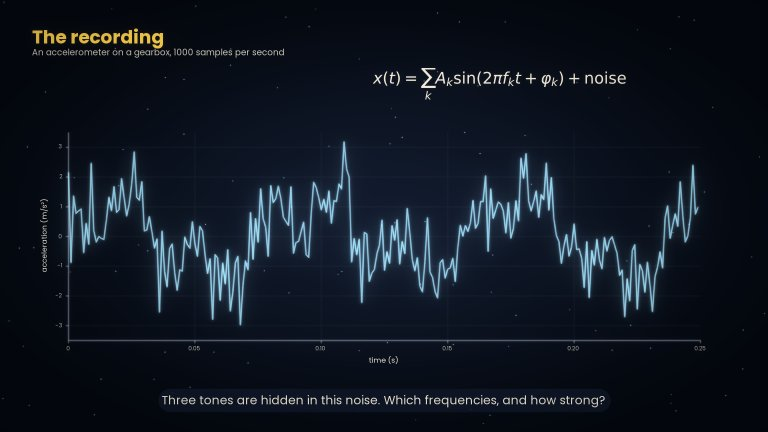

In [8]:
s1 = film.scenes[0]
s1.name = "Recording"
film.add("title", text="The recording", subtitle="An accelerometer on a gearbox, 1000 samples per second",
         start=0.2)
ax1 = film.add("axes", name="Signal", position=(170, 330), size=(1580, 520), x_range=(0, 0.25),
               y_range=(-3.5, 3.5), x_label="time (s)", y_label="acceleration (m/s²)", y_ticks=7, start=0.4)
rec = film.add("curve", name="Recorded", axes=ax1, source="data", data="assets/signal.csv", x_column="t",
               y_column="recorded", color="ice", width=1.6, start=0.9)
rec.enter_duration = 3.0
film.add("equation", tex=r"x(t) = \sum_k A_k \sin(2\pi f_k t + \varphi_k) + \mathrm{noise}",
         position=(1250, 210), size=40, start=4.2)
film.add("caption", text="Three tones are hidden in this noise. Which frequencies, and how strong?", style="box",
         start=4.6, end=8.8)
show(s1, 6.0)

### Scene 2: a sum of sines, seen from the side

The classic picture of the Fourier transform. In front, the signal is the sum of three sines; the sines slide
back to their frequencies, and the camera turns until time points at the viewer. From the side each sine is a
single bar at its frequency, as tall as its amplitude: that view is the spectrum.

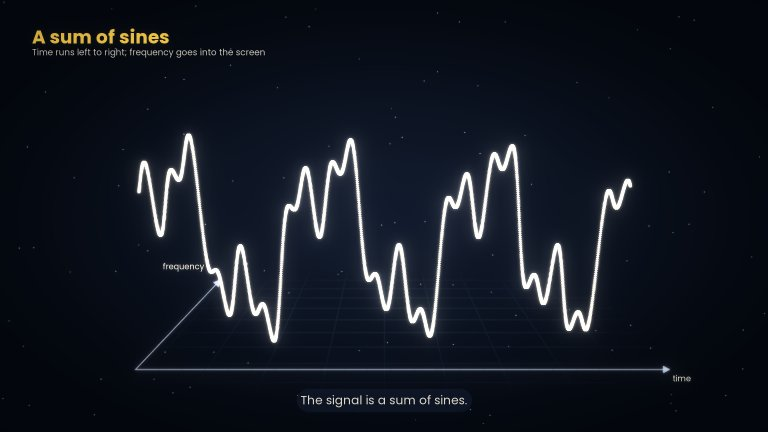

In [9]:
s2 = film.add_scene("Sum of sines", 12.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="A sum of sines", subtitle="Time runs left to right; frequency goes into the screen",
         start=0.2)
cam = s2.camera
cam.set("target", (0, 28, 0)).set("fov", 32).set("elevation", 12)
cam.key("azimuth", 0, -90).key("azimuth", 3.5, -90).key("azimuth", 7.0, -30, "in_out").key("azimuth", 9.5, 0,
                                                                                               "in_out")
cam.key("distance", 0, 150).key("distance", 7.0, 190, "in_out").key("distance", 9.5, 820, "in_out")
cam.key("fov", 0, 32).key("fov", 7.0, 32).key("fov", 9.5, 7.9, "in_out")      # far and narrow: nearly flat
cam.key("elevation", 0, 8).key("elevation", 7.0, 16, "in_out").key("elevation", 9.5, 3, "in_out")
film.add("grid3d", center=(0, 30, -22), size=(100, 90), divisions=10, start=0.3)
film.add("arrow3d", tail=(-42, 0, -22), tip=(48, 0, -22), color="gray", start=0.3)
film.add("arrow3d", tail=(-42, 0, -22), tip=(-42, 66, -22), color="gray", start=0.3)
film.add("label3d", point=(48, 0, -22), text="time", leader=False, dot=False, offset=(10, 10), start=0.3)
film.add("label3d", point=(-42, 66, -22), text="frequency", leader=False, dot=False, offset=(-40, -20),
         start=0.3)
total = film.add("pointcloud", name="Sum", data="assets/sum.csv", color="cream", size=1.8, style="solid",
                 start=0.5)
total.key("opacity", 5.6, 1.0).key("opacity", 7.0, 0.0)              # the sum fades once the tones are apart
for i, ((f, a, _), color) in enumerate(zip(est, TONE_COLORS)):
    tone = film.add("pointcloud", name=f"{f:.1f} Hz", data=f"assets/tone_{i}.csv", color=color, size=1.8,
                    style="solid", start=2.0 + 0.3 * i)
    tone.key("center", 2.6 + 0.3 * i, (0, 0, 0)).key("center", 5.0 + 0.3 * i, (0, f * FY, 0), "in_out")
    tone.key("opacity", 9.4, 1.0).key("opacity", 10.4, 0.3)
    film.add("arrow3d", tail=(44, f * FY, 0), tip=(44, f * FY, a * AZ + 0.01), color=color, width=6,
             head_size=12, start=9.4 + 0.2 * i)
    film.add("label3d", point=(44, f * FY, a * AZ), text=f"{f:.1f} Hz", color=color, size=24, leader=False,
             dot=False, offset=(-30, -34), start=9.6 + 0.2 * i)
film.add("caption", text="The signal is a sum of sines.", style="box", start=0.8, end=4.5)
film.add("caption", text="Seen from the side, each sine is one bar at its frequency: the spectrum.", style="box",
         start=8.0, end=11.8)
show(s2, 1.5)

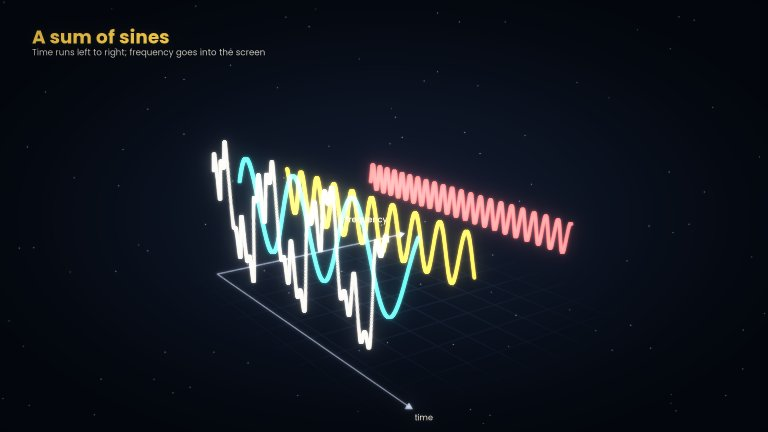

In [10]:
show(s2, 6.0)

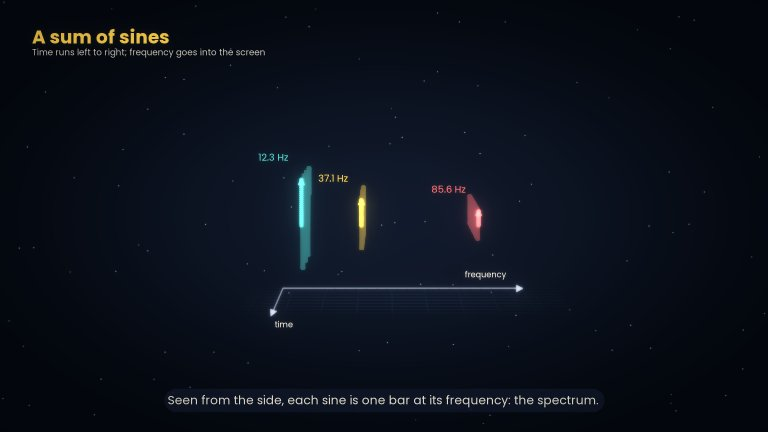

In [11]:
show(s2, 10.8)

### Scene 3: the spectrum

The amplitude spectrum of the whole 2 s recording, with the peaks found in step 3 and the detection threshold.

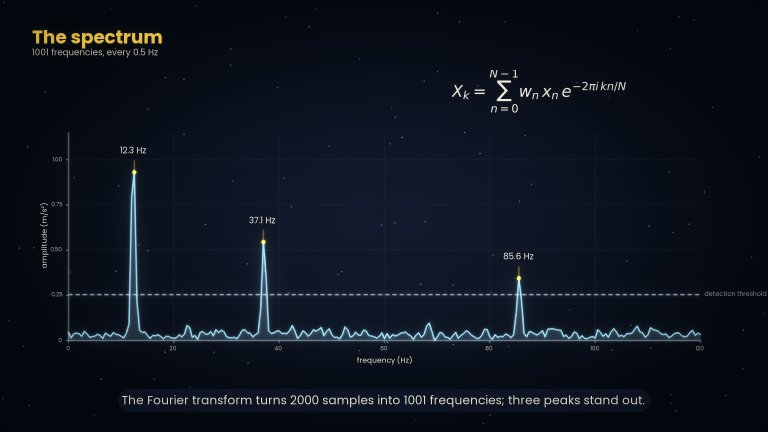

In [12]:
s3 = film.add_scene("Spectrum", 9.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="The spectrum", subtitle=f"{freqs.size} frequencies, every {DF} Hz", start=0.2)
ax3 = film.add("axes", name="Spectrum", position=(170, 330), size=(1580, 520), x_range=(0, 120),
               y_range=(0, 1.15), x_label="frequency (Hz)", y_label="amplitude (m/s²)", x_ticks=6, y_ticks=5,
               start=0.4)
film.add("spectrum", name="Amplitude", axes=ax3, source="data", data="assets/spectrum.csv", x_column="f",
         y_column="amplitude", peaks=", ".join(f"{f:.2f}" for f in peak_f),
         peak_labels=", ".join(f"{f:.1f} Hz" for f in peak_f), label_size=22, color="ice", start=0.9)
film.add("guide", axes=ax3, orientation="horizontal", value=threshold, color="gray", dashed=True,
         label="detection threshold", start=3.0)
film.add("equation", tex=r"X_k = \sum_{n=0}^{N-1} w_n\, x_n\, e^{-2\pi i\, kn/N}", position=(1350, 230), size=40,
         start=2.2)
film.add("caption", text=f"The Fourier transform turns {N} samples into {freqs.size} frequencies; three peaks "
                         "stand out.", style="box", start=1.0, end=8.8)
show(s3, 6.0)

### Scene 4: filtering

The mask keeps only the bins around the peaks (top). Transformed back, the recording (grey) becomes the
filtered signal (teal), and the signal-to-noise ratio counts up.

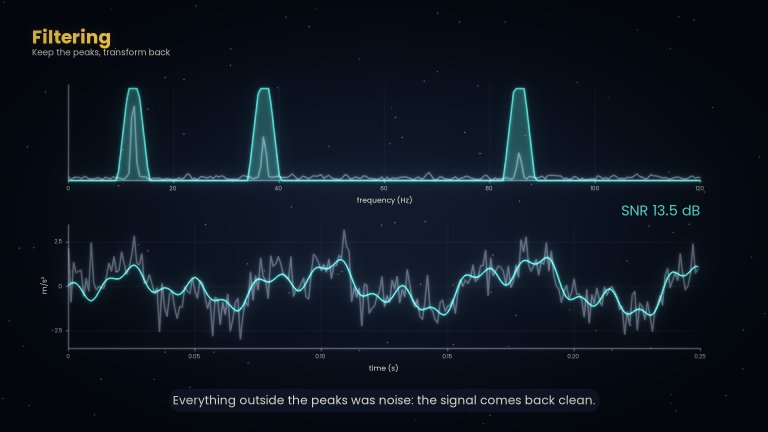

In [13]:
s4 = film.add_scene("Filtering", 11.0, transition="wipe_left", transition_duration=0.8)
film.add("title", text="Filtering", subtitle="Keep the peaks, transform back", start=0.2)
ax4a = film.add("axes", name="Mask", position=(170, 210), size=(1580, 240), x_range=(0, 120), y_range=(0, 1.2),
                x_label="frequency (Hz)", y_label="", y_ticks=0, x_ticks=6, start=0.3)
film.add("curve", axes=ax4a, source="data", data="assets/spectrum.csv", x_column="f", y_column="amplitude",
         color="gray", width=1.5, start=0.5)
film.add("curve", name="Mask", axes=ax4a, source="data", data="assets/spectrum.csv", x_column="f",
         y_column="mask", color="teal", width=2, fill_opacity=0.25, start=1.4)
ax4b = film.add("axes", name="Signals", position=(170, 560), size=(1580, 310), x_range=(0, 0.25),
                y_range=(-3.5, 3.5), x_label="time (s)", y_label="m/s²", y_ticks=3, start=2.4)
film.add("curve", axes=ax4b, source="data", data="assets/signal.csv", x_column="t", y_column="recorded",
         color="gray", width=1.2, start=2.6)
filt = film.add("curve", name="Filtered", axes=ax4b, source="data", data="assets/signal.csv", x_column="t",
                y_column="filtered", color="teal", width=2.6, start=4.0)
filt.enter_duration = 2.5
snr = film.add("text", name="SNR", text="SNR {value:.1f} dB", position=(1750, 500), size=36, color="teal",
               align="right", start=4.0)
snr.key("value", 4.0, snr_raw).key("value", 6.5, snr_filtered, "in_out")
film.add("caption", text="Everything outside the peaks was noise: the signal comes back clean.", style="box",
         start=6.8, end=10.8)
show(s4, 8.0)

### Scene 5: the result

The fitted tones, with their uncertainties, next to the truth, and bars of their amplitudes.

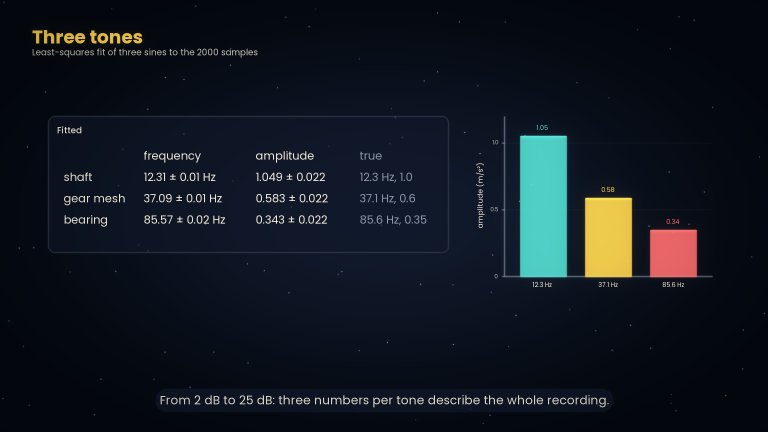

In [14]:
s5 = film.add_scene("Result", 8.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="Three tones", subtitle="Least-squares fit of three sines to the 2000 samples", start=0.2)
film.add("panel", title="Fitted", position=(120, 290), size=(1000, 340), start=0.4)
rows = [("", "frequency", "amplitude", "true")]
rows += [(name, f"{f:.2f} ± {df:.2f} Hz", f"{a:.3f} ± {da:.3f}", f"{tf} Hz, {ta}")
         for name, (f, a, _), (df, da, _), (tf, ta, _) in zip(NAMES, est, est_err, TRUE)]
for col, x in enumerate((160, 360, 640, 900)):
    film.add("text", text="\n".join(r[col] for r in rows), position=(x, 370), size=28, line_spacing=1.9,
             color="gray" if col == 3 else "cream", start=0.9 + 0.2 * col)
ax5 = film.add("axes", name="Amplitudes", position=(1260, 290), size=(520, 400), x_range=(0.4, 3.6),
               y_range=(0, 1.2), x_label="", y_label="amplitude (m/s²)", x_ticks=0, y_ticks=4, start=0.6)
film.add("bars", axes=ax5, values=", ".join(f"{a:.3f}" for a in est[:, 1]),
         labels=", ".join(f"{f:.1f} Hz" for f in est[:, 0]), colors=", ".join(TONE_COLORS), value_labels=True,
         value_format="{value:.2f}", start=1.4)
film.add("caption", text=f"From {snr_raw:.0f} dB to {snr_model:.0f} dB: three numbers per tone describe the whole "
                         "recording.", style="box", start=2.0, end=7.8)
show(s5, 5.0)

## Check, preview and render

no problems
5 scenes, 45.8 s: Recording, Sum of sines, Spectrum, Filtering, Result



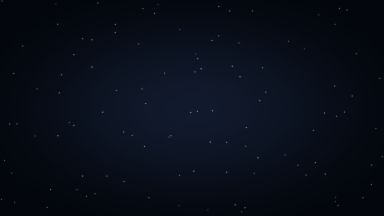

In [15]:
print(film.validate() or "no problems")
print(f"{len(film.scenes)} scenes, {film.duration:.1f} s:", ", ".join(sc.name for sc in film.scenes))
film.save()
film.preview(fps=3, scale=0.2)

In [16]:
video = film.render(FILM / "fourier.mp4", scale=0.5)
print(f"wrote {video} ({video.stat().st_size / 1e6:.1f} MB)")

wrote films/fourier/fourier.mp4 (2.6 MB)
